# 12 — Class Imbalance & Probability Calibration (MVP First)

**Goals:** negative sampling / positive weighting ablation, independent **user-disjoint validation tuning vs calibration** partition ordered by **last pre-cutoff user interaction timestamp**, Platt and Isotonic calibration, Brier/LogLoss/ECE/reliability curves, ranking preservation and export.

**Important scientific limitations:** (1) This is *not* true prospective forward-time calibration: all validation users share the same snapshot cutoff; ordering users by their last historical activity is only a time-ordered proxy. (2) Notebook 10/11 models were already selected using the **entire** validation set, so the new calibration subset is not wholly independent of upstream model selection. A rigorous production study requires new chronological model-development, calibration, and untouched test windows with model retraining. (3) RetailRocket provides no impression logs: calibrated probabilities mean *future eligible interaction among the fixed retrieved candidates*, **not CTR/CVR**. (4) Weak implicit negatives and retrieval conditioning limit probability interpretation.

**MVP:** Existing models are calibrated without retraining; optional ablation trains small DeepFM variants from scratch on Notebook 09 train only. Never fit or select on test.

In [1]:
from pathlib import Path
import json, time, copy, random, warnings
import numpy as np, pandas as pd, duckdb, joblib, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
SEED=42; np.random.seed(SEED);random.seed(SEED);torch.manual_seed(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
cwd=Path.cwd().resolve();ROOT=next((p for p in (cwd,*cwd.parents) if (p/'data'/'processed'/'notebook02.duckdb').exists()),None)
assert ROOT is not None,'Run from project root or notebooks folder'
OUT=ROOT/'data'/'processed';REPORT=ROOT/'data'/'reports';MODELS=ROOT/'models';PLOTS=REPORT/'notebook12_plots'
for p in (REPORT,MODELS,PLOTS):p.mkdir(parents=True,exist_ok=True)
manifest=json.loads((REPORT/'notebook09_feature_manifest.json').read_text(encoding='utf8'))
FEATS=manifest['feature_columns'];CATS=manifest['categorical_columns'];NUMS=[f for f in FEATS if f not in CATS]
SPLITS=('train','validation','test');KS=(20,50,100)
print('ROOT:',ROOT,'DEVICE:',DEVICE)

ROOT: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks DEVICE: cuda


## 1. Load and align all fixed-candidate predictions

Only needed columns are loaded; joins validate `(user_id,item_id)` uniqueness. Prediction scores are **not** probabilities unless separately calibrated.

In [2]:
DATA={};SCORES={};audit=[]
for split in SPLITS:
    p=OUT/f'{split}_ranking_features_top500.parquet';assert p.exists(),p
    d=pd.read_parquet(p,columns=list(dict.fromkeys(['user_id','item_id','label','retrieval_rank']+FEATS)))
    d=d.sort_values(['user_id','retrieval_rank'],kind='stable').reset_index(drop=True)
    assert not d[['user_id','item_id']].duplicated().any()
    sizes=d.groupby('user_id',sort=False).size();assert sizes.min()==sizes.max()==500
    DATA[split]=d;SCORES[split]={}
    predpaths={'rrf':OUT/f'{split}_lightgbm_rrf_baseline_top500.parquet',
        'lightgbm_binary':OUT/f'{split}_lightgbm_binary_top500.parquet',
        'lightgbm_lambdarank':OUT/f'{split}_lightgbm_lambdarank_top500.parquet',
        'deepfm':OUT/f'{split}_deepfm_deepfm_top500.parquet'}
    for method,fp in predpaths.items():
        assert fp.exists(),fp
        t=pd.read_parquet(fp,columns=['user_id','item_id','score'])
        assert not t[['user_id','item_id']].duplicated().any()
        merged=d[['user_id','item_id']].merge(t,on=['user_id','item_id'],how='left',validate='one_to_one',sort=False)
        assert len(merged)==len(d) and merged.score.notna().all()
        SCORES[split][method]=merged.score.to_numpy(dtype=np.float64)
    audit.append(dict(split=split,rows=len(d),users=d.user_id.nunique(),positives=int(d.label.sum()),group_size=500))
display(pd.DataFrame(audit))

,split,rows,users,positives,group_size
0,train,2055000,4110,2131,500
1,validation,1828500,3657,1996,500
2,test,1786000,3572,1785,500


## 2. Time-ordered user-disjoint validation partition

Use each validation user's **last pre-cutoff interaction** (`validation_history`), sort ascending, then assign earlier 50% to **tuning** and later 50% to **calibration**. No labels or future interactions determine the partition. Tuning is for choosing new ablation settings; calibration is for fitting calibration mappings. The final test remains untouched until all choices are frozen.

**Caveat:** last activity time is a proxy for temporal ordering of users, not a separate prospective target window.

In [3]:
con=duckdb.connect(str(OUT/'notebook02.duckdb'),read_only=True)
print('validation_history columns:',con.execute('DESCRIBE validation_history').df()[['column_name','column_type']].to_dict('records'))
history_cols=set(con.execute('DESCRIBE validation_history').df()['column_name'])
time_col=next((c for c in ('last_ts','ts','timestamp') if c in history_cols),None)
if time_col is None:
    raise ValueError(f'No supported history timestamp column found: {sorted(history_cols)}')
last=con.execute(f'SELECT user_id, MAX({time_col}) AS last_pre_cutoff_ts FROM validation_history GROUP BY user_id').df()
last=last[last.user_id.isin(DATA['validation'].user_id.unique())].copy()
assert last.user_id.nunique()==DATA['validation'].user_id.nunique(),'Missing validation users in history'
last=last.sort_values(['last_pre_cutoff_ts','user_id'],kind='stable').reset_index(drop=True)
cut=len(last)//2
TUNE_USERS=set(last.user_id.iloc[:cut].tolist());CAL_USERS=set(last.user_id.iloc[cut:].tolist())
assert not(TUNE_USERS&CAL_USERS) and len(TUNE_USERS|CAL_USERS)==len(last)
V=DATA['validation'];TUNE_MASK=V.user_id.isin(TUNE_USERS).to_numpy();CAL_MASK=V.user_id.isin(CAL_USERS).to_numpy()
assert (TUNE_MASK^CAL_MASK).all()
partition=last.assign(partition=np.where(last.index<cut,'tuning','calibration'))
partition.to_csv(REPORT/'notebook12_validation_partition.csv',index=False)
print(partition.groupby('partition').agg(users=('user_id','nunique'),min_last_event=('last_pre_cutoff_ts','min'),max_last_event=('last_pre_cutoff_ts','max')))
print('Candidate positive rates:',{'tuning':float(V.label.to_numpy()[TUNE_MASK].mean()),'calibration':float(V.label.to_numpy()[CAL_MASK].mean())})

validation_history columns: [{'column_name': 'user_id', 'column_type': 'BIGINT'}, {'column_name': 'item_id', 'column_type': 'BIGINT'}, {'column_name': 'n_events', 'column_type': 'BIGINT'}, {'column_name': 'last_ts', 'column_type': 'BIGINT'}]
             users  min_last_event  max_last_event
partition                                         
calibration   1829   1439313568404   1439922070672
tuning        1828   1437331632397   1439312599735
Candidate positive rates: {'tuning': 0.0007330415754923413, 'calibration': 0.0014499726626571896}


## 3. Metrics and calibration utilities

ECE uses equal-frequency bins to handle extreme imbalance. Also export bin statistics for reliability diagrams. PR-AUC is average precision on the fixed candidate pool. AUC/PR-AUC and top-K ranking should stay unchanged for **strictly increasing** calibration; isotonic can introduce ties.

In [4]:
EPS=1e-7

def sigmoid(x):
    x=np.clip(np.asarray(x,dtype=np.float64),-50,50)
    return 1/(1+np.exp(-x))

def reliability(y,p,n_bins=15):
    y=np.asarray(y,dtype=np.int8);p=np.clip(np.asarray(p,dtype=np.float64),EPS,1-EPS)
    order=np.argsort(p,kind='stable');chunks=np.array_split(order,n_bins)
    return pd.DataFrame([dict(bin=i+1,n=len(idx),mean_pred=float(p[idx].mean()),observed_rate=float(y[idx].mean()),positives=int(y[idx].sum()))
                         for i,idx in enumerate(chunks) if len(idx)])

def probability_metrics(y,p):
    y=np.asarray(y,dtype=np.int8);p=np.clip(np.asarray(p,dtype=np.float64),EPS,1-EPS)
    rel=reliability(y,p)
    return dict(brier=float(brier_score_loss(y,p)),logloss=float(log_loss(y,p,labels=[0,1])),
                ece=float(np.average(np.abs(rel.mean_pred-rel.observed_rate),weights=rel.n)),
                pr_auc=float(average_precision_score(y,p)),positive_rate=float(y.mean()))

def ndcg20_on_subset(scores,mask):
    d=DATA['validation'].loc[mask,['user_id','item_id','label','retrieval_rank']].copy()
    d['score']=np.asarray(scores)[mask]
    d=d.sort_values(['user_id','score','retrieval_rank','item_id'],ascending=[True,False,True,True],kind='stable')
    d['rank']=d.groupby('user_id',sort=False).cumcount()+1
    # Eligible future positives (not only retrieved positives) as Notebook 11.
    sub_users=d.user_id.drop_duplicates().to_numpy()
    elig=con.execute('SELECT user_id, COUNT(*) AS n FROM validation_positives GROUP BY user_id').df().set_index('user_id')['n']
    ideal=elig.reindex(sub_users).to_numpy(dtype=np.int64)
    dcg=d.loc[d['rank']<=20].assign(discount=lambda t:t.label/np.log2(t['rank']+1)).groupby('user_id')['discount'].sum().reindex(sub_users,fill_value=0).to_numpy()
    discount=np.r_[0.,np.cumsum(1/np.log2(np.arange(2,22)))];idcg=discount[np.minimum(ideal,20)]
    return float(np.mean(dcg/idcg))

def score_to_base_prob(method,s):
    x=SCORES[s][method]
    # Sigmoid is a score-only diagnostic for logits; LightGBM binary already outputs probabilities.
    if method=='lightgbm_binary':return np.clip(x,EPS,1-EPS)
    if method=='deepfm':return np.clip(sigmoid(x),EPS,1-EPS)
    return np.clip(sigmoid(x),EPS,1-EPS)

print('Validation tune DeepFM NDCG@20:',ndcg20_on_subset(SCORES['validation']['deepfm'],TUNE_MASK))

Validation tune DeepFM NDCG@20: 0.037478123454976774


## 4. Class imbalance ablation — optional GPU training

**Fast MVP switch:** `RUN_ABLATION=True` trains four compact DeepFM variants with train-only preprocessing. It uses the same architecture and feature transforms as Notebook 11, but new independent training runs; evaluation on the **tuning** partition only. Negative sampling is performed **per user**, keeping all positive candidates. `pos_weight` is an additional cost-sensitive loss weight and can distort probabilities; **do not assume it is a probability correction**.

Set `RUN_ABLATION=False` for a quick calibration-only pass.

In [5]:
RUN_ABLATION=True
ABLATION_EPOCHS=8
ABLATION_PATIENCE=2
ABLATION_CONFIGS=[('sample_60_weight_1',60,1.0),('sample_60_weight_3',60,3.0),('sample_30_weight_1',30,1.0),('sample_120_weight_1',120,1.0)]
BATCH_SIZE=8192 if DEVICE.type=='cuda' else 4096
EVAL_BATCH=16384 if DEVICE.type=='cuda' else 8192
# Preprocessing strictly fitted on Notebook09 train, using Notebook11's saved checkpoint transforms.
ckpt=torch.load(MODELS/'notebook11_deepfm_checkpoint.pt',map_location='cpu',weights_only=False)
assert ckpt['num_features']==NUMS and ckpt['categorical_features']==CATS
VOCABS=ckpt['category_vocabularies'];CARD=ckpt['category_cardinalities']
med=np.asarray(ckpt['numeric_median']);logmask=np.asarray(ckpt['numeric_log_mask'],dtype=bool)
lo=np.asarray(ckpt['numeric_clip_low']);hi=np.asarray(ckpt['numeric_clip_high'])
mu=np.asarray(ckpt['numeric_mean']);sigma=np.asarray(ckpt['numeric_std'])
def transform(d):
    x=d[NUMS].to_numpy(dtype=np.float64,copy=True);x=np.where(np.isfinite(x),x,med)
    x[:,logmask]=np.log1p(np.maximum(x[:,logmask],0));x=np.clip(x,lo,hi)
    x=np.clip((x-mu)/sigma,-8,8).astype(np.float32)
    cat=np.stack([pd.to_numeric(d[c],errors='coerce').fillna(-1).astype('int64').map(VOCABS[c]).fillna(0).to_numpy(dtype=np.int64) for c in CATS],axis=1)
    for j in range(len(CATS)):assert cat[:,j].min()>=0 and cat[:,j].max()<CARD[j]
    return x,cat
XNUM={};XCAT={};Y={}
if RUN_ABLATION:
    for s in ('train','validation'):
        XNUM[s],XCAT[s]=transform(DATA[s]);Y[s]=DATA[s].label.to_numpy(dtype=np.float32)
print('Ablation enabled:',RUN_ABLATION)

Ablation enabled: True


In [6]:
class DeepFM(nn.Module):
    def __init__(self,n_num,cards,dim=8,hidden=64,dropout=.35):
        super().__init__();self.num_linear=nn.Parameter(torch.zeros(n_num));self.num_fm=nn.Parameter(torch.randn(n_num,dim)*.01)
        self.cat_linear=nn.ModuleList([nn.Embedding(c,1,padding_idx=0) for c in cards])
        self.cat_fm=nn.ModuleList([nn.Embedding(c,dim,padding_idx=0) for c in cards]);self.bias=nn.Parameter(torch.zeros(()))
        self.deep=nn.Sequential(nn.Linear(n_num+len(cards)*dim,hidden),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,hidden//2),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden//2,1))
        for e in list(self.cat_linear)+list(self.cat_fm):nn.init.normal_(e.weight,std=.01);e.weight.data[0].zero_()
    def forward(self,x,cat):
        linear=(x*self.num_linear).sum(1)+self.bias
        embeddings=[x.unsqueeze(-1)*self.num_fm.unsqueeze(0)];deep_c=[]
        for j,(e1,e2) in enumerate(zip(self.cat_linear,self.cat_fm)):
            linear=linear+e1(cat[:,j]).squeeze(-1);z=e2(cat[:,j]);embeddings.append(z.unsqueeze(1));deep_c.append(z)
        z=torch.cat(embeddings,dim=1)
        fm=.5*((z.sum(dim=1)**2-z.square().sum(dim=1)).sum(dim=1))
        return linear+fm+self.deep(torch.cat([x]+deep_c,dim=1)).squeeze(-1)

def sample_indices(ratio,seed):
    rng=np.random.default_rng(seed);indices=[]
    for idx in DATA['train'].groupby('user_id',sort=False).indices.values():
        idx=np.asarray(idx);pos=idx[Y['train'][idx]>0];neg=idx[Y['train'][idx]==0]
        count=min(len(neg),max(20,len(pos)*ratio))
        indices.extend(pos.tolist());indices.extend(rng.choice(neg,size=count,replace=False).tolist())
    result=np.asarray(indices,dtype=np.int64);rng.shuffle(result);return result

@torch.no_grad()
def ablation_predict(model):
    model.eval();idx=np.flatnonzero(TUNE_MASK);out=np.empty(len(idx),dtype=np.float32)
    for a in range(0,len(idx),EVAL_BATCH):
        take=idx[a:a+EVAL_BATCH]
        out[a:a+len(take)]=model(torch.from_numpy(XNUM['validation'][take]).to(DEVICE),torch.from_numpy(XCAT['validation'][take]).to(DEVICE)).cpu().numpy()
    return out

def fit_ablation(name,ratio,weight,seed):
    torch.manual_seed(seed);rng_idx=sample_indices(ratio,seed)
    loader=DataLoader(TensorDataset(torch.from_numpy(XNUM['train'][rng_idx]),torch.from_numpy(XCAT['train'][rng_idx]),torch.from_numpy(Y['train'][rng_idx])),batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
    model=DeepFM(len(NUMS),CARD,dim=8,hidden=64,dropout=.35).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=1e-4)
    pos_weight=torch.tensor([weight],dtype=torch.float32,device=DEVICE)
    best=-np.inf;best_epoch=0;best_state=None;wait=0
    for epoch in range(1,ABLATION_EPOCHS+1):
        model.train()
        for xn,xc,y in loader:
            xn=xn.to(DEVICE);xc=xc.to(DEVICE);y=y.to(DEVICE)
            opt.zero_grad(set_to_none=True);logits=model(xn,xc)
            loss=nn.functional.binary_cross_entropy_with_logits(logits,y,pos_weight=pos_weight)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step()
        scores=ablation_predict(model)
        full=np.zeros(len(DATA['validation']),dtype=np.float32);full[TUNE_MASK]=scores
        metric=ndcg20_on_subset(full,TUNE_MASK)
        print(f'{name} epoch={epoch} tune_NDCG20={metric:.5f}')
        if metric>best+1e-6:
            best=metric;best_epoch=epoch;best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};wait=0
        else:
            wait+=1
            if wait>=ABLATION_PATIENCE:break
    model.load_state_dict(best_state)
    return dict(variant=name,negative_per_positive=ratio,pos_weight=weight,train_rows=len(rng_idx),sampled_positive_rate=float(Y['train'][rng_idx].mean()),best_epoch=best_epoch,tuning_ndcg20=best),model

ablation_rows=[];ablation_models={}
if RUN_ABLATION:
    for i,(name,ratio,weight) in enumerate(ABLATION_CONFIGS):
        start=time.perf_counter();result,mod=fit_ablation(name,ratio,weight,SEED+i)
        result['seconds']=round(time.perf_counter()-start,2);ablation_rows.append(result)
        ablation_models[name]=mod.cpu();torch.cuda.empty_cache() if DEVICE.type=='cuda' else None
ablation_df=pd.DataFrame(ablation_rows)
if not ablation_df.empty:
    display(ablation_df.sort_values('tuning_ndcg20',ascending=False))
    for name,mod in ablation_models.items():
        torch.save({'state_dict':mod.state_dict(),'config':next(r for r in ablation_rows if r['variant']==name),'num_features':NUMS,'categorical_features':CATS,'category_cardinalities':CARD},MODELS/f'notebook12_ablation_{name}.pt')
else:print('Ablation skipped')


sample_60_weight_1 epoch=1 tune_NDCG20=0.00518
sample_60_weight_1 epoch=2 tune_NDCG20=0.00816
sample_60_weight_1 epoch=3 tune_NDCG20=0.02492
sample_60_weight_1 epoch=4 tune_NDCG20=0.03207
sample_60_weight_1 epoch=5 tune_NDCG20=0.03411
sample_60_weight_1 epoch=6 tune_NDCG20=0.03598
sample_60_weight_1 epoch=7 tune_NDCG20=0.03668
sample_60_weight_1 epoch=8 tune_NDCG20=0.03625
sample_60_weight_3 epoch=1 tune_NDCG20=0.00483
sample_60_weight_3 epoch=2 tune_NDCG20=0.02957
sample_60_weight_3 epoch=3 tune_NDCG20=0.03564
sample_60_weight_3 epoch=4 tune_NDCG20=0.03692
sample_60_weight_3 epoch=5 tune_NDCG20=0.03802
sample_60_weight_3 epoch=6 tune_NDCG20=0.03780
sample_60_weight_3 epoch=7 tune_NDCG20=0.03820
sample_60_weight_3 epoch=8 tune_NDCG20=0.03809
sample_30_weight_1 epoch=1 tune_NDCG20=0.00957
sample_30_weight_1 epoch=2 tune_NDCG20=0.01265
sample_30_weight_1 epoch=3 tune_NDCG20=0.02057
sample_30_weight_1 epoch=4 tune_NDCG20=0.02742
sample_30_weight_1 epoch=5 tune_NDCG20=0.03157
sample_30_wei

,variant,negative_per_positive,pos_weight,train_rows,sampled_positive_rate,best_epoch,tuning_ndcg20,seconds
1,sample_60_weight_3,60,3.0,180836,0.011784,7,0.038202,27.75
0,sample_60_weight_1,60,1.0,180836,0.011784,7,0.036677,30.21
3,sample_120_weight_1,120,1.0,288962,0.007375,8,0.036178,39.16
2,sample_30_weight_1,30,1.0,121132,0.017592,8,0.035718,19.19


## 5. Calibrate the **frozen** Notebook 10/11 models

Platt scaling fits logistic regression on one scalar score; isotonic regression is monotonic nonparametric calibration. To avoid fitting and evaluating calibration on the same examples, split the **calibration partition again**, in last-activity order, into `cal_fit` (first 60%) and `cal_check` (remaining 40%). Calibration method is selected using `cal_check` **Brier**, then the selected calibrator is refitted on all calibration users before **one** final test evaluation. Tuning partition is reserved for ablations and diagnostics.

**Caveat:** earlier Notebook 10/11 model selection already used the full validation population; this is an independent *calibration fit/evaluation split*, not a completely untouched upstream holdout.

In [7]:
cal_order=partition.loc[partition.partition=='calibration','user_id'].tolist()
cal_n=int(len(cal_order)*.6)
CAL_FIT_USERS=set(cal_order[:cal_n]);CAL_CHECK_USERS=set(cal_order[cal_n:])
FIT_MASK=V.user_id.isin(CAL_FIT_USERS).to_numpy();CHECK_MASK=V.user_id.isin(CAL_CHECK_USERS).to_numpy()
assert (FIT_MASK&CHECK_MASK).sum()==0 and np.all((FIT_MASK|CHECK_MASK)==CAL_MASK)
print('cal-fit users:',len(CAL_FIT_USERS),'cal-check users:',len(CAL_CHECK_USERS))

def fit_platt(x,y):
    m=LogisticRegression(C=1.,max_iter=400,solver='lbfgs')
    m.fit(np.asarray(x).reshape(-1,1),y);return m

def fit_isotonic(x,y):
    m=IsotonicRegression(y_min=EPS,y_max=1-EPS,out_of_bounds='clip')
    m.fit(np.asarray(x),y);return m

def calibrated(m,method,x):
    if method=='platt':return m.predict_proba(np.asarray(x).reshape(-1,1))[:,1]
    if method=='isotonic':return m.predict(np.asarray(x))
    raise ValueError(method)

cal_trials=[];calibrators={};calibration_predictions={}
yv=V.label.to_numpy(dtype=np.int8)
for source in ('lightgbm_binary','deepfm'):
    scores=SCORES['validation'][source]
    base=score_to_base_prob(source,'validation')
    for method in ('uncalibrated','platt','isotonic'):
        if method=='uncalibrated':
            probs=base[CHECK_MASK];model=None
        else:
            model=fit_platt(scores[FIT_MASK],yv[FIT_MASK]) if method=='platt' else fit_isotonic(scores[FIT_MASK],yv[FIT_MASK])
            probs=calibrated(model,method,scores[CHECK_MASK])
        result=probability_metrics(yv[CHECK_MASK],probs)
        cal_trials.append(dict(source=source,calibrator=method,subset='cal_check',**result))
cal_trials_df=pd.DataFrame(cal_trials)
display(cal_trials_df.sort_values(['source','brier']))
SELECTED={}
for source in ('lightgbm_binary','deepfm'):
    trials=cal_trials_df.query('source==@source').sort_values(['brier','calibrator'],kind='stable')
    winner=str(trials.iloc[0].calibrator);SELECTED[source]=winner
    if winner!='uncalibrated':
        # Refit after selection, using all calibration users; never test.
        model=fit_platt(SCORES['validation'][source][CAL_MASK],yv[CAL_MASK]) if winner=='platt' else fit_isotonic(SCORES['validation'][source][CAL_MASK],yv[CAL_MASK])
        calibrators[source]=model
        joblib.dump(model,MODELS/f'notebook12_{source}_{winner}_calibrator.joblib')
    print('Selected',source,'=>',winner)


cal-fit users: 1097 cal-check users: 732


,source,calibrator,subset,brier,logloss,ece,pr_auc,positive_rate
5,deepfm,isotonic,cal_check,0.001987,0.012476,0.000814,0.024008,0.002014
4,deepfm,platt,cal_check,0.001989,0.012453,0.000812,0.026491,0.002014
3,deepfm,uncalibrated,cal_check,0.002479,0.018117,0.009010,0.026491,0.002014
0,lightgbm_binary,uncalibrated,cal_check,0.001987,0.012583,0.001003,0.027765,0.002014
2,lightgbm_binary,isotonic,cal_check,0.001990,0.012395,0.000463,0.022380,0.002014
1,lightgbm_binary,platt,cal_check,0.002010,0.014823,0.001946,0.027765,0.002014


Selected lightgbm_binary => uncalibrated
Selected deepfm => isotonic


## 6. Reliability diagrams and calibration quality

Show out-of-sample **cal_check** reliability curves for the methods before final refit. These are more interpretable than plotting the fit partition. Use logarithmic axes only if probabilities permit; here plots use linear scale to avoid hiding zeros.

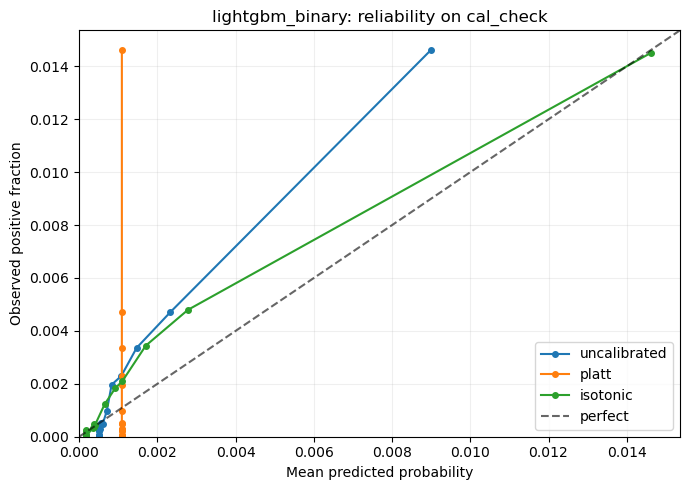

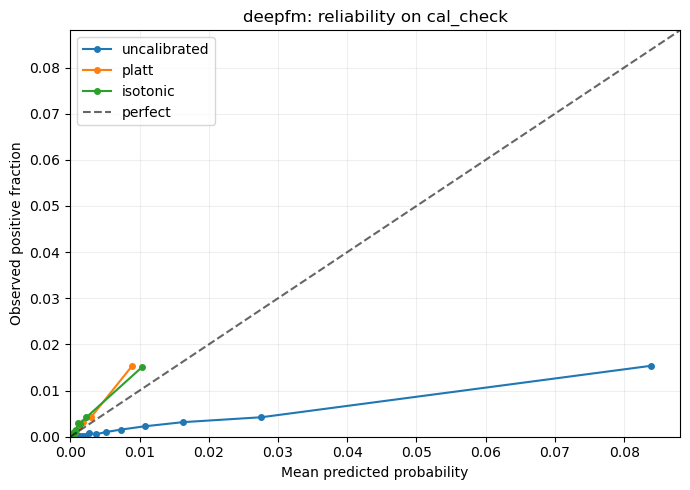

In [8]:
bin_exports=[]
for source in ('lightgbm_binary','deepfm'):
    fig,ax=plt.subplots(figsize=(7,5))
    for method in ('uncalibrated','platt','isotonic'):
        scores=SCORES['validation'][source]
        if method=='uncalibrated':p=score_to_base_prob(source,'validation')[CHECK_MASK]
        else:
            fit=fit_platt(scores[FIT_MASK],yv[FIT_MASK]) if method=='platt' else fit_isotonic(scores[FIT_MASK],yv[FIT_MASK])
            p=calibrated(fit,method,scores[CHECK_MASK])
        bins=reliability(yv[CHECK_MASK],p)
        bins.insert(0,'calibrator',method);bins.insert(0,'source',source);bin_exports.append(bins)
        ax.plot(bins.mean_pred,bins.observed_rate,'o-',label=method,markersize=4)
    lim=max(.002, min(.25,max(ax.get_xlim()[1],ax.get_ylim()[1])))
    ax.plot([0,lim],[0,lim],'k--',alpha=.6,label='perfect')
    ax.set(xlim=(0,lim),ylim=(0,lim),xlabel='Mean predicted probability',ylabel='Observed positive fraction',title=f'{source}: reliability on cal_check')
    ax.legend();ax.grid(alpha=.2);fig.tight_layout()
    fig.savefig(PLOTS/f'notebook12_reliability_{source}.png',dpi=160)
    plt.show();plt.close(fig)
reliability_df=pd.concat(bin_exports,ignore_index=True)
reliability_df.to_csv(REPORT/'notebook12_reliability_bins.csv',index=False)

## 7. Freeze choices → test confirmation (once)

Final test comparison: raw scores converted to baseline probabilities and frozen selected calibrators. Calibration is **not** optimized using test. Report ranking@20 before and after; Platt with positive slope preserves order, isotonic may create ties.

In [9]:
test_rows=[];prediction_exports=[]
for source in ('lightgbm_binary','deepfm'):
    raw=SCORES['test'][source]
    before=score_to_base_prob(source,'test')
    winner=SELECTED[source]
    after=before if winner=='uncalibrated' else calibrated(calibrators[source],winner,raw)
    y=DATA['test'].label.to_numpy(dtype=np.int8)
    for name,p in [('uncalibrated',before),('selected_calibration',after)]:
        metrics=probability_metrics(y,p)
        test_rows.append(dict(source=source,variant=name,calibrator=winner if name=='selected_calibration' else 'none',**metrics))
    out=DATA['test'][['user_id','item_id','label','retrieval_rank']].copy()
    out['raw_score']=raw;out['uncalibrated_probability']=before;out['calibrated_probability']=after
    file=OUT/f'test_notebook12_{source}_calibrated_top500.parquet'
    out.to_parquet(file,index=False,compression='zstd')
    prediction_exports.append(dict(source=source,path=file.name,rows=len(out)))
    # Per-user rank consistency check, including isotonic ties.
    rank0=out.groupby('user_id',sort=False)['raw_score'].rank(ascending=False,method='first')
    rank1=out.groupby('user_id',sort=False)['calibrated_probability'].rank(ascending=False,method='first')
    print(source,'selected:',winner,'fraction changed within-user ranks:',float((rank0!=rank1).mean()))
test_df=pd.DataFrame(test_rows)
display(test_df)


lightgbm_binary selected: uncalibrated fraction changed within-user ranks: 0.0
deepfm selected: isotonic fraction changed within-user ranks: 0.9343510638297873


,source,variant,calibrator,brier,logloss,ece,pr_auc,positive_rate
0,lightgbm_binary,uncalibrated,none,0.000991,0.006911,0.000372,0.014597,0.000999
1,lightgbm_binary,selected_calibration,uncalibrated,0.000991,0.006911,0.000372,0.014597,0.000999
2,deepfm,uncalibrated,none,0.001347,0.011703,0.006665,0.015456,0.000999
3,deepfm,selected_calibration,isotonic,0.000991,0.006889,0.000173,0.014054,0.000999


## 8. Save reports and artifacts

Calibration method selection is based on **cal_check Brier Score**; the new imbalance ablation selection uses **tuning NDCG@20**. The ablation models are **diagnostic only** and are not silently substituted for the frozen DeepFM used in calibration.

In [10]:
ablation_df.to_csv(REPORT/'notebook12_imbalance_ablation.csv',index=False)
cal_trials_df.to_csv(REPORT/'notebook12_calibration_trials.csv',index=False)
test_df.to_csv(REPORT/'notebook12_test_calibration_metrics.csv',index=False)
report={
 'notebook':'12_class_imbalance_probability_calibration','seed':SEED,'device':str(DEVICE),
 'partition':{'method':'user-disjoint ordered by last pre-cutoff validation interaction',
              'tuning_users':len(TUNE_USERS),'calibration_users':len(CAL_USERS),
              'cal_fit_users':len(CAL_FIT_USERS),'cal_check_users':len(CAL_CHECK_USERS),
              'strict_prospective_temporal_split':False,'upstream_models_selected_on_full_validation':True},
 'ablation':{'enabled':RUN_ABLATION,'configurations':ABLATION_CONFIGS,'results':ablation_df.to_dict('records')},
 'calibration':{'selection_metric':'cal_check Brier score','selected':SELECTED,'trials':cal_trials_df.to_dict('records')},
 'test':{'used_for_selection_or_fitting':False,'metrics':test_df.to_dict('records')},
 'prediction_exports':prediction_exports,
 'outputs':{'ablation_csv':'notebook12_imbalance_ablation.csv','calibration_csv':'notebook12_calibration_trials.csv',
            'test_csv':'notebook12_test_calibration_metrics.csv','reliability_csv':'notebook12_reliability_bins.csv',
            'validation_partition_csv':'notebook12_validation_partition.csv',
            'plots':['notebook12_reliability_lightgbm_binary.png','notebook12_reliability_deepfm.png']},
 'limitations':['No impression logs; predicted probabilities are not CTR or CVR',
                'Validation partition ordered by last user activity, not truly prospective target periods',
                'Notebook10/11 models were previously selected on entire validation set; cal_check is not fully independent of upstream model selection',
                'Weak negatives, candidate-conditioning and sampled DeepFM training affect probability meaning',
                'Isotonic may create ties; calibration does not aim to improve ranking',
                'Ablation models are not used to select frozen calibration source']}
path=REPORT/'notebook12_calibration_report.json'
path.write_text(json.dumps(report,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf8')
print('Saved:',path)
print('Models:',list(MODELS.glob('notebook12_*')))
print('Plots:',list(PLOTS.glob('notebook12_*')))

Saved: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\data\reports\notebook12_calibration_report.json
Models: [WindowsPath('C:/YR_Python_Code/multi-stage-ads-recommendation/notebooks/models/notebook12_ablation_sample_120_weight_1.pt'), WindowsPath('C:/YR_Python_Code/multi-stage-ads-recommendation/notebooks/models/notebook12_ablation_sample_30_weight_1.pt'), WindowsPath('C:/YR_Python_Code/multi-stage-ads-recommendation/notebooks/models/notebook12_ablation_sample_60_weight_1.pt'), WindowsPath('C:/YR_Python_Code/multi-stage-ads-recommendation/notebooks/models/notebook12_ablation_sample_60_weight_3.pt'), WindowsPath('C:/YR_Python_Code/multi-stage-ads-recommendation/notebooks/models/notebook12_deepfm_isotonic_calibrator.joblib')]
Plots: [WindowsPath('C:/YR_Python_Code/multi-stage-ads-recommendation/notebooks/data/reports/notebook12_plots/notebook12_reliability_deepfm.png'), WindowsPath('C:/YR_Python_Code/multi-stage-ads-recommendation/notebooks/data/reports/notebook12_plots/note

## Next steps

1. Upload `data/reports/notebook12_calibration_report.json` for analysis.
2. If the best epoch is the maximum or models appear unstable, expand ablation epochs only after this MVP passes.
3. For a **strict chronological** calibration study, create new forward target windows, retrain upstream rankers without those windows, reserve a separate later calibration window, and evaluate once on an untouched subsequent test window.
4. Do **not** describe these probabilities as online CTR/CVR or apply them to expected revenue without impression/exposure logging and a matching serving population.